In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Create sample raw data
data = {
    'Customer': ['Arun', 'Priya', 'Kumar', 'Divya', 'Arun',
                 'Rahul', 'Priya', 'Vijay', 'Meena', 'Kumar'],
    'City': ['Chennai', 'Vellore', 'chennai', 'Katpadi', 'Chennai',
             'Vellore', 'VELLORE', 'Arcot', 'Arcot', 'Katpadi'],
    'Sales': [1200, 1500, np.nan, 900, 1200,
              1800, 1500, np.nan, 1100, 950],
    'Category': ['Clothing', 'Electronics', 'Clothing', 'Food',
                 'Clothing', 'Food', 'Electronics', 'Clothing',
                 'Food', 'Clothing']
}

df = pd.DataFrame(data)

# Add a duplicate record
df = pd.concat([df, df.iloc[[0]]], ignore_index=True)

df.to_csv('raw_sales_data.csv', index=False)

print("Raw dataset created!")
print("Dataset shape:", df.shape)
display(df)

Raw dataset created!
Dataset shape: (11, 4)


,Customer,City,Sales,Category
0,Arun,Chennai,1200.0,Clothing
1,Priya,Vellore,1500.0,Electronics
2,Kumar,chennai,NaN,Clothing
3,Divya,Katpadi,900.0,Food
4,Arun,Chennai,1200.0,Clothing
5,Rahul,Vellore,1800.0,Food
6,Priya,VELLORE,1500.0,Electronics
7,Vijay,Arcot,NaN,Clothing
8,Meena,Arcot,1100.0,Food
9,Kumar,Katpadi,950.0,Clothing


Clean the data

In [2]:
# Store original data for comparison
original_rows = len(df)
missing_before = int(df.isnull().sum().sum())

# Remove duplicate records
df = df.drop_duplicates().copy()

# Standardize text columns
df['Customer'] = df['Customer'].str.strip().str.title()
df['City'] = df['City'].str.strip().str.title()
df['Category'] = df['Category'].str.strip().str.title()

# Fill missing sales with the median
df['Sales'] = df['Sales'].fillna(df['Sales'].median())

# Save cleaned dataset
df.to_csv('cleaned_sales_data.csv', index=False)

print("DATA CLEANING COMPLETED")
print("Original rows:", original_rows)
print("Rows after removing duplicates:", len(df))
print("Missing values before cleaning:", missing_before)
print("Missing values after cleaning:", df.isnull().sum().sum())

display(df)

DATA CLEANING COMPLETED
Original rows: 11
Rows after removing duplicates: 9
Missing values before cleaning: 2
Missing values after cleaning: 0


,Customer,City,Sales,Category
0,Arun,Chennai,1200.0,Clothing
1,Priya,Vellore,1500.0,Electronics
2,Kumar,Chennai,1200.0,Clothing
3,Divya,Katpadi,900.0,Food
5,Rahul,Vellore,1800.0,Food
6,Priya,Vellore,1500.0,Electronics
7,Vijay,Arcot,1200.0,Clothing
8,Meena,Arcot,1100.0,Food
9,Kumar,Katpadi,950.0,Clothing


Generate automated summary reports

In [3]:
# Summary by city
city_report = df.groupby('City').agg(
    Total_Sales=('Sales', 'sum'),
    Average_Sales=('Sales', 'mean'),
    Number_of_Records=('Sales', 'count')
).round(2).reset_index()

# Summary by category
category_report = df.groupby('Category').agg(
    Total_Sales=('Sales', 'sum'),
    Average_Sales=('Sales', 'mean')
).round(2).reset_index()

print("SALES REPORT BY CITY")
display(city_report)

print("SALES REPORT BY CATEGORY")
display(category_report)

city_report.to_csv('city_sales_report.csv', index=False)
category_report.to_csv('category_sales_report.csv', index=False)

print("Reports exported successfully!")

SALES REPORT BY CITY


,City,Total_Sales,Average_Sales,Number_of_Records
0,Arcot,2300.0,1150.0,2
1,Chennai,2400.0,1200.0,2
2,Katpadi,1850.0,925.0,2
3,Vellore,4800.0,1600.0,3


SALES REPORT BY CATEGORY


,Category,Total_Sales,Average_Sales
0,Clothing,4550.0,1137.50
1,Electronics,3000.0,1500.00
2,Food,3800.0,1266.67


Reports exported successfully!


Create a visualization

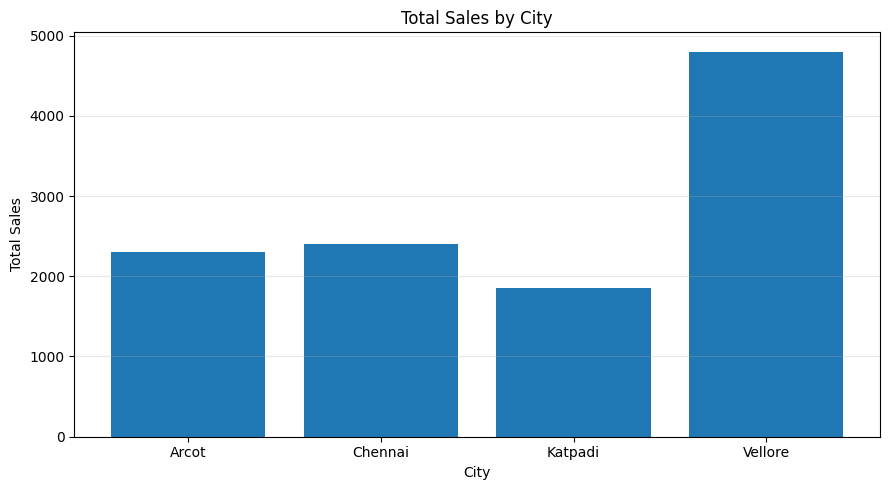

In [4]:
plt.figure(figsize=(9, 5))

plt.bar(city_report['City'], city_report['Total_Sales'])

plt.title('Total Sales by City')
plt.xlabel('City')
plt.ylabel('Total Sales')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Create a cleaning report

In [5]:
cleaning_report = pd.DataFrame({
    'Metric': [
        'Original Rows',
        'Rows After Cleaning',
        'Duplicate Rows Removed',
        'Missing Sales Before Cleaning',
        'Missing Values After Cleaning',
        'Total Sales After Cleaning'
    ],
    'Value': [
        original_rows,
        len(df),
        original_rows - len(df),
        missing_before,
        int(df.isnull().sum().sum()),
        round(df['Sales'].sum(), 2)
    ]
})

display(cleaning_report)
cleaning_report.to_csv('data_cleaning_report.csv', index=False)

print("FINAL CLEANING REPORT GENERATED!")

,Metric,Value
0,Original Rows,11.0
1,Rows After Cleaning,9.0
2,Duplicate Rows Removed,2.0
3,Missing Sales Before Cleaning,2.0
4,Missing Values After Cleaning,0.0
5,Total Sales After Cleaning,11350.0


FINAL CLEANING REPORT GENERATED!


## Conclusion

This project automates data cleaning and reporting using Python and Pandas. Missing values were handled using median imputation, duplicate records were removed, and inconsistent text entries were standardized. Automated reports were generated to summarize sales by city and category. A bar chart was used to visualize sales performance. This workflow demonstrates how data preprocessing and reporting automation can improve data quality and reduce manual effort.